# VaR and ES of a portfolio: sign convention, historical simulation and a first exceedance count

- **Level:** 1, Fundamentals
- **Prerequisites:** notebook 01 of topic 01 (install and open an artifact)
- **Reading time:** about 30 minutes

**Question:** In the 251 trading days of the 2008 crisis year, how often did a one-day 99 percent value at risk of a euro position fail, and is that count compatible with a forecast that is right?

## Objectives

By the end of this notebook you can:

- state the two sign conventions of market risk, say which one the engine stores and which one the committed documents hold, and convert between them with the engine's own function;
- compute a value at risk (VaR) and an expected shortfall (ES) from a sample of returns, and say how many observations the tail estimate really rests on;
- produce a one-step historical-simulation forecast that uses no information from the forecast day or after it;
- count the exceedances of a VaR forecast, compare the count with the expected one, and read the Kupiec proportion-of-failures test;
- rebuild the exceedance flags of a committed forecast, including a window whose realised returns are not committed.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools, print the versions they run with and fix the words this notebook prints for the engine's
# lights
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is case C11 (VaR and ES forecasting and back-testing) as Contraste commits it. Two files are read.

- `data/derived/C11/fx-2008.json`: a long position in the euro against the US dollar, July 2008 to June 2009, 251 forecast days. The daily returns are the simple change of the Federal Reserve H.10 exchange rate (licence class `mirror-allowed`), so the file **commits the realised losses**. This is the file where every number of this notebook can be recomputed from the returns.
- `data/derived/C11/calm-2004-06.json`: a mixed book (50 percent US equity, 30 percent 10-year Treasury, 20 percent euro) over the calm years 2004 to 2006, 750 forecast days. One of its components is the Kenneth French equity return, a **derived-only** source: the file keeps the forecasts of the 17 models and their exceedance days, and withholds the realised losses.

Both files carry the forecasts of every model of the ladder that Contraste ran (the estimators are the subject of notebook 02). Here we use one: `hs-250`, historical simulation on the last 250 days. The next cell loads the two files and prints what they hold.

In [2]:
# Load the two committed windows of case C11 (the notebook sits three folders below the repository root) and
# describe them
ROOT = Path("../../..").resolve()
C11 = ROOT / "data" / "derived" / "C11"
fx = json.loads((C11 / "fx-2008.json").read_text(encoding="utf-8"))
calm = json.loads((C11 / "calm-2004-06.json").read_text(encoding="utf-8"))

STATUS = {"included": "committed", "withheld-derived-only": "withheld, derived only"}
for label, doc in (("fx-2008", fx), ("calm-2004-06", calm)):
    out = doc["outputs"]
    dates = out["grid"]["dates"]
    print(label, "|", out["window"]["n_forecast_days"], "forecast days", "|", dates[0], "to", dates[-1])
    status = STATUS[out["grid"]["realised_loss"]["status"]]
    print("  realised losses:", status, "| models:", len(out["models"]))
print("riskvalidation", doc["provenance"]["riskvalidation_version"], "| installed", rv.__version__)

fx-2008 | 251 forecast days | 2008-07-01 to 2009-06-30
  realised losses: committed | models: 17
calm-2004-06 | 750 forecast days | 2004-01-02 to 2006-12-29
  realised losses: withheld, derived only | models: 17
riskvalidation 1.0.1 | installed 1.0.1


## Method

### Step 1: two ways to write the same number

Market-risk literature uses two sign conventions, and mixing them is the most common silent error in a VaR report.

- **Loss convention** (Basel, McNeil, Frey and Embrechts): the loss is $L = -X$ for a return $X$, the confidence level $\alpha$ is near 1 (0.99, 0.975) and VaR and ES are positive numbers.
- **Return convention** (Patton, Ziegel and Chen, 2019): the tail level $\alpha$ is small (0.01, 0.025), $v = F^{-1}(\alpha)$ is the VaR and $e = \frac{1}{\alpha}\int_0^{\alpha} F^{-1}(u)\,du$ is the ES, both negative in practice, with $e \le v$.

The engine stores forecasts in the **return convention**, because the scoring loss of notebook 05 needs it, and flips the sign in one place only, at the reporting layer. The committed documents hold **positive loss numbers**, as decimals of the portfolio value: a VaR of 0.0144 means 1.44 percent of the portfolio. The next cell reads the declaration in the file and applies the engine's two conversion functions to a committed forecast.

In [3]:
# Convert three committed VaR values between the two sign conventions with the engine's own functions
from riskvalidation.market.conventions import from_loss_numbers, to_loss_numbers

CONVENTION = {"return-negative": "negative return", "positive-loss": "positive loss"}
sign = fx["outputs"]["sign_convention"]
print("engine stores:", CONVENTION[sign["engine_convention"]], "|",
      "document stores:", CONVENTION[sign["document_convention"]])
hs250 = {m["model_id"]: m for m in fx["outputs"]["models"]}["hs-250"]
level_1pct = hs250["by_level"][0]
var_doc = np.array(level_1pct["var"][:3])
var_engine = from_loss_numbers(var_doc)
print("committed VaR, loss numbers:", var_doc)
print("as the engine holds it:", var_engine)
print("back to loss numbers:", to_loss_numbers(var_engine))

engine stores: negative return | document stores: positive loss
committed VaR, loss numbers: [0.01438435 0.01438435 0.01438435]
as the engine holds it: [-0.01438435 -0.01438435 -0.01438435]
back to loss numbers: [0.01438435 0.01438435 0.01438435]


### Step 2: VaR and ES from a sample

With $N$ returns sorted $r_{(1)} \le \dots \le r_{(N)}$ and $k = \lceil \alpha N \rceil$, the empirical VaR is the $k$-th smallest return and the empirical ES is the tail integral of the empirical quantile function, in which the $k$-th return carries only the fraction of weight left over (the engine's `var_es_from_sample`, `market/conventions.py`):

$$\widehat{\mathrm{VaR}}_\alpha = r_{(k)}, \qquad \widehat{\mathrm{ES}}_\alpha = \frac{\sum_{i<k} r_{(i)} + (\alpha N - (k-1))\, r_{(k)}}{\alpha N}$$

The sample is the 251 realised returns of the euro position, $y = -\text{loss}$. The cell calls the engine at both tail levels and prints the weights the tail estimate rests on: weight 1 on each of the first $k-1$ returns and the leftover on the $k$-th.

In [4]:
# VaR and ES of the 251 realised returns at both tail levels, with the weights the tail estimate rests on
from riskvalidation.market.conventions import var_es_from_sample

loss = np.array(fx["outputs"]["grid"]["realised_loss"]["loss"])
y = -loss
n = y.size
print("returns:", n, "| mean:", round(float(y.mean()), 6), "| standard deviation:", round(float(y.std()), 6))
for alpha in (0.01, 0.025):
    var, es = var_es_from_sample(y, alpha)
    k = int(np.ceil(alpha * n - 1e-9))
    weights = np.append(np.ones(k - 1), alpha * n - (k - 1))
    print(f"alpha {alpha}: k = {k}, alpha N = {alpha * n:.3f}, weights {weights.round(3)}")
    print(f"  VaR {-var:.6f} | ES {-es:.6f} (in loss numbers)")

returns: 251 | mean: -0.000407 | standard deviation: 0.010608
alpha 0.01: k = 3, alpha N = 2.510, weights [1.   1.   0.51]
  VaR 0.023915 | ES 0.027216 (in loss numbers)
alpha 0.025: k = 7, alpha N = 6.275, weights [1.    1.    1.    1.    1.    1.    0.275]
  VaR 0.020861 | ES 0.024265 (in loss numbers)


A 1 percent tail on 251 days is $\alpha N = 2.51$ observations: the VaR is the third worst day and the ES averages the two worst days and 0.51 of the third. The estimate is exact as a definition and fragile as a measurement. The next cell removes the single worst day and recomputes, to show how far one observation moves the tail at each level.

alpha 0.01: VaR -5.9% | ES -9.3%
alpha 0.025: VaR -2.3% | ES -5.8%


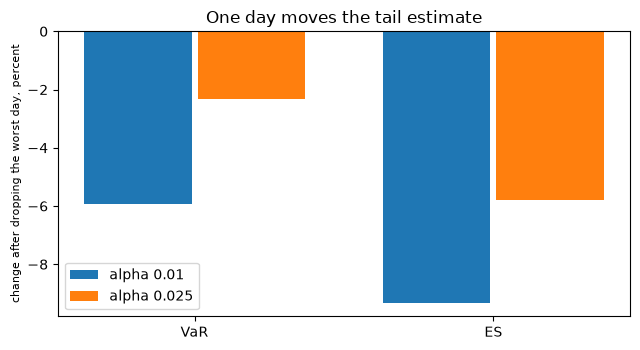

In [5]:
# Remove the single worst day and recompute VaR and ES: how far one observation moves the tail estimate
trimmed = np.delete(y, int(np.argmin(y)))
shift = {}
for alpha in (0.01, 0.025):
    var_all, es_all = var_es_from_sample(y, alpha)
    var_cut, es_cut = var_es_from_sample(trimmed, alpha)
    shift[alpha] = (100 * (var_cut / var_all - 1), 100 * (es_cut / es_all - 1))
    print(f"alpha {alpha}: VaR {shift[alpha][0]:.1f}% | ES {shift[alpha][1]:.1f}%")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for offset, alpha in enumerate(shift):
    ax.bar(np.arange(2) + 0.38 * offset - 0.19, shift[alpha], width=0.36, label=f"alpha {alpha}")
ax.set_xticks(np.arange(2))
ax.set_xticklabels(["VaR", "ES"])
ax.set_ylabel("change after dropping the worst day, percent", fontsize=8)
ax.set_title("One day moves the tail estimate")
ax.legend()
fig.tight_layout()
plt.show()

The bars show the percentage change of the estimate when the worst day of the year is dropped from the sample. The ES moves more than the VaR at both levels, and the 1 percent level moves more than the 2.5 percent one, because the smaller the tail the fewer days it averages. The figure does not say which estimate is right, only that an estimate resting on two or three days is fragile; the same fragility sits behind every back-test of a 1 percent forecast on one year of data.

### Step 3: a one-step historical-simulation forecast

A forecast is a statement made **before** the day it is about. Historical simulation takes the returns of the last $W$ days as the scenarios for tomorrow, and reads the VaR and ES of that sample. For the forecast of day $t$ the engine's `historical_var_es(returns, alpha, window)` must receive only the returns dated before $t$, most recent last; giving it day $t$ itself would make the back-test meaningless.

Contraste's rung `hs-250` uses 250 days, and its first estimation window ends before the file starts. The file holds only 251 days, so here we use a shorter window, $W = 100$, and forecast the last 151 days from returns inside the file. The window is a choice of this notebook; the committed `hs-250` is read in step 5.

alpha 0.01: forecast days 151
  exceedances 1 | expected 1.51
alpha 0.025: forecast days 151
  exceedances 4 | expected 3.78


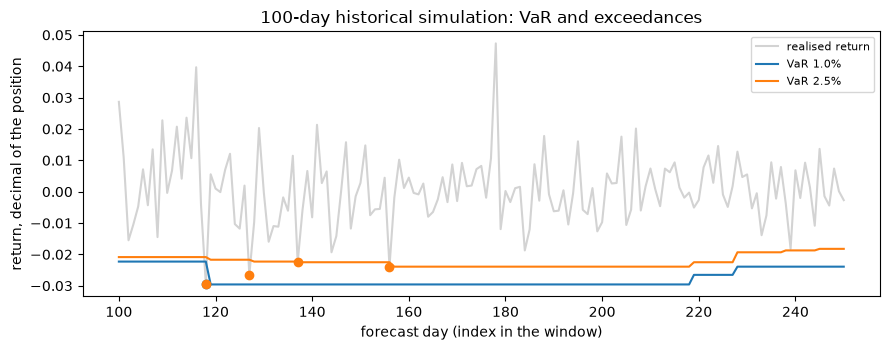

In [6]:
# Forecast each day from the previous W returns only (no look-ahead), flag the exceedances and draw the VaR path
from riskvalidation.market.historical import historical_var_es

W = 100
days = np.arange(W, n)
forecasts = {}
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(days, y[W:], color="lightgrey", label="realised return")
for alpha in (0.01, 0.025):
    var_path = np.array([historical_var_es(y[:t], alpha, W)[0] for t in range(W, n)])
    flags = y[W:] < var_path
    forecasts[alpha] = flags
    line, = ax.plot(days, var_path, label=f"VaR {alpha:.1%}")
    ax.scatter(days[flags], y[W:][flags], color=line.get_color(), zorder=3)
    print(f"alpha {alpha}: forecast days {flags.size}")
    print(f"  exceedances {int(flags.sum())} | expected {alpha * flags.size:.2f}")
ax.set_xlabel("forecast day (index in the window)")
ax.set_ylabel("return, decimal of the position")
ax.set_title("100-day historical simulation: VaR and exceedances")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The line is the VaR the 100-day window gave each morning and the dots are the days on which the realised return fell below it. The 1 percent level has its single exceedance on day 118, the worst return of the file; from the next morning that day sits in the window and both VaR lines step down, and 100 days later it leaves the window and they step back up. A historical VaR therefore reacts only after the loss, and stays conservative for exactly as long as the loss stays in the window; the count of dots is the quantity the next step tests.

### Step 4: the Kupiec test of the exceedance count

If the VaR is right, each day has probability $\alpha$ of an exceedance, independently, so the count $x$ in $T$ days is binomial with parameters $T$ and $\alpha$. Kupiec (1995) compares the observed share $\hat\pi = x/T$ with $\alpha$ through a likelihood ratio:

$$LR_{POF} = -2\ln\frac{(1-\alpha)^{T-x}\,\alpha^{x}}{(1-\hat\pi)^{T-x}\,\hat\pi^{x}} \;\xrightarrow{d}\; \chi^2_1$$

The engine's `kupiec_pof(exceedances, alpha)` returns this statistic, its asymptotic p-value, and in `metric` the **exact** binomial p-value, which matters when the expected count is small (the asymptotic law is a poor guide with an expected count of 1.5). Its light is a Contraste internal gate on the asymptotic p-value (amber below 0.10, red below 0.05), not a regulatory threshold. The next cell runs it on the two forecasts of step 3.

In [7]:
# Kupiec proportion-of-failures test on the exceedance flags of step 3: statistic, asymptotic and exact
# p-values, light
from riskvalidation.validation.market import kupiec_pof

for alpha, flags in forecasts.items():
    result = kupiec_pof(flags, alpha, model_id="hs-100")
    expected = result.extras["expected_events"]
    print(f"alpha {alpha}: exceedances {result.n_events} / {result.n} | expected {expected:.2f}")
    print(f"  LR_POF {result.statistic:.4f} | p asymptotic {result.p_value:.4f} | p exact {result.metric:.4f}")
    print(f"  light: {LIGHT[result.light.value]}")

alpha 0.01: exceedances 1 / 151 | expected 1.51
  LR_POF 0.1975 | p asymptotic 0.6567 | p exact 1.0000
  light: green
alpha 0.025: exceedances 4 / 151 | expected 3.78
  LR_POF 0.0135 | p asymptotic 0.9075 | p exact 0.7927
  light: green


### Step 5: the committed forecast on the crisis year

Contraste's committed `hs-250` forecast for the same euro position lets us repeat the count on the real ladder. The committed VaR is a positive loss number, so a day is an exceedance when the realised loss is **above** it. The cell rebuilds the flags from the realised losses of this file, runs Kupiec on them at both levels and counts how many of the exceedances fall inside the first 100 days, which the forecast of step 3 does not score.

In [8]:
# Rebuild the exceedance flags of the committed hs-250 forecast from the realised losses and run Kupiec on them
for level in hs250["by_level"]:
    alpha = level["alpha"]
    flags = loss > np.array(level["var"])
    result = kupiec_pof(flags, alpha, model_id="hs-250")
    early = int(np.sum(np.flatnonzero(flags) < W))
    expected = level["expected_exceedances"]
    print(f"alpha {alpha}: exceedances {int(flags.sum())} of {flags.size} | expected {expected:.2f}")
    print(f"  p {result.p_value:.6f} | light {LIGHT[result.light.value]} | exceedances before day {W}: {early}")

alpha 0.01: exceedances 10 of 251 | expected 2.51
  p 0.000330 | light red | exceedances before day 100: 6
alpha 0.025: exceedances 13 of 251 | expected 6.28
  p 0.017215 | light red | exceedances before day 100: 9


### Step 6: a window whose returns are not committed

The calm window holds a Kenneth French return, so its realised losses are withheld. The artifact still stores, for each model and level, the **days on which the loss exceeded the VaR** (`exceedance_days`, indices into the 750 forecast dates) and the VaR path. That is everything the exceedance tests need: a test of the count reads flags, not returns. We rebuild the 750 flags from the stored days, count them, and rerun Kupiec.

In [9]:
# Rebuild the 750 flags of the calm window from the stored exceedance days and run Kupiec on them
calm_hs = {m["model_id"]: m for m in calm["outputs"]["models"]}["hs-250"]
dates = calm["outputs"]["grid"]["dates"]
for level in calm_hs["by_level"]:
    alpha = level["alpha"]
    flags = np.zeros(level["n_scored"], dtype=bool)
    flags[level["exceedance_days"]] = True
    result = kupiec_pof(flags, alpha, model_id="hs-250")
    expected = level["expected_exceedances"]
    print(f"alpha {alpha}: {flags.size} days | exceedances {int(flags.sum())} | expected {expected:.2f}")
    print(f"  first {dates[level['exceedance_days'][0]]}, last {dates[level['exceedance_days'][-1]]}")
    print(f"  p {result.p_value:.6f} | p exact {result.metric:.4f} | light {LIGHT[result.light.value]}")

alpha 0.01: 750 days | exceedances 9 | expected 7.50
  first 2004-03-10, last 2006-06-05
  p 0.593559 | p exact 0.5777 | light green
alpha 0.025: 750 days | exceedances 22 | expected 18.75
  first 2004-01-28, last 2006-07-05
  p 0.459214 | p exact 0.4127 | light green


The last cell draws both windows. On the left, the euro position: the realised loss each day (bars), the committed `hs-250` VaR and ES at 1 percent (lines), and the exceedance days (red dots). On the right, the calm window: the committed VaR path at 1 percent and the days on which the loss exceeded it. The two panels have different scales on purpose: they are different portfolios.

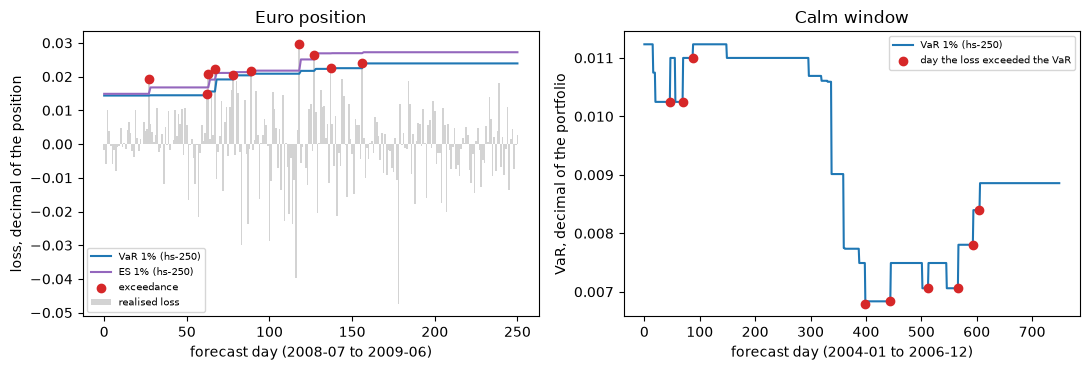

In [10]:
# Draw both windows: the euro position against its committed hs-250 forecast, and the calm window's VaR path
# with its exceedances
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))
day = np.arange(loss.size)
var_fx, es_fx = np.array(level_1pct["var"]), np.array(level_1pct["es"])
hit = loss > var_fx
left.bar(day, loss, color="lightgrey", width=1.0, label="realised loss")
left.plot(day, var_fx, color="tab:blue", label="VaR 1% (hs-250)")
left.plot(day, es_fx, color="tab:purple", label="ES 1% (hs-250)")
left.scatter(day[hit], loss[hit], color="tab:red", zorder=3, label="exceedance")
left.set_xlabel("forecast day (2008-07 to 2009-06)")
left.set_ylabel("loss, decimal of the position")
left.set_title("Euro position")
left.legend(fontsize=7)

calm_level = calm_hs["by_level"][0]
var_calm = np.array(calm_level["var"])
right.plot(var_calm, color="tab:blue", label="VaR 1% (hs-250)")
right.scatter(calm_level["exceedance_days"], var_calm[calm_level["exceedance_days"]], color="tab:red", zorder=3,
              label="day the loss exceeded the VaR")
right.set_xlabel("forecast day (2004-01 to 2006-12)")
right.set_ylabel("VaR, decimal of the portfolio")
right.set_title("Calm window")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

In the left panel the VaR and the ES of the committed 250-day window stay flat for long stretches and step up only after a red dot: the ten exceedances all fall in the first 160 days of the year, and each one lifts the forecast that the next loss then has to beat. In the right panel three exceedances come early, with the VaR above 0.010, and six after day 395, when a year of calm has pulled the VaR down to its lowest levels, between 0.007 and 0.009. The panels use different scales on purpose, since they are different portfolios; what they show together is that a historical VaR is least protective right after quiet markets, and that the count alone does not say whether exceedances come in bunches, which the next notebook tests.

## Results

**Answer:** No. At the 0.01 tail level the committed historical simulation exceeded its VaR on 10 of 251 days where 2.51 were expected, and Kupiec rejects a correct forecast with a p-value of 0.000330 (red); at the 0.025 level the count is 13 against 6.28 (p 0.017215, red). The 100-day simulation of step 3, scored on the calmer last 151 days, had 1 exceedance against 1.51 expected and passes (p 0.6567).

- **Convention.** The committed VaR is a positive loss number (0.01438435 on the first days of the euro window) and the engine holds it as a negative return (-0.01438435); the second function returns the committed number. A report that does not state which convention it uses is ambiguous by a sign.
- **The tail rests on a few days.** On the 251 returns the 0.01 VaR is 0.023915 of the position and the ES 0.027216, and the tail weights are 1, 1 and 0.51, so three days carry the estimate. Dropping the worst day moves the VaR by -5.9% and the ES by -9.3% at 0.01, and by -2.3% and -5.8% at 0.025: the ES is the more fragile of the two, and a short window makes it more so.
- **A first count.** The 100-day simulation had 1 exceedance at 0.01 (1.51 expected) and 4 at 0.025 (3.78 expected), and Kupiec does not reject (p 0.6567 and 0.9075). With one exceedance the exact p-value (1.0000) and the asymptotic one (0.6567) are far apart, the small-count case that the engine reports beside the asymptotic value.
- **The crisis year.** Of the 10 committed exceedances at 0.01, 6 fall in the first 100 days, which the forecast of step 3 never scores; at 0.025, 9 of 13 do. The two counts are made on different days and cannot be compared one to one.
- **The calm window.** The same rung has 9 exceedances at 0.01 in 750 days (7.50 expected, p 0.593559, green) and 22 at 0.025 (18.75 expected, p 0.459214, green). The flags rebuilt from the stored exceedance days alone are enough for the count test, so a window whose returns are withheld by licence can still be tested for its count.

What this notebook does not show: the dependence between exceedances (notebook 03), the ES forecast (notebook 04), the other estimators (notebook 02) or how to rank them (notebook 05).

## Summary

- The engine stores VaR and ES in the return convention (negative numbers) and the committed documents hold positive loss numbers; `to_loss_numbers` and `from_loss_numbers` are the only place the sign changes.
- A sample VaR is an order statistic and the ES a tail average with a fractional weight on the last observation; at 1 percent on about 250 days they rest on two or three days, so one observation moves them visibly.
- A forecast is made from information dated before the day it is about. Counting how often the realised loss exceeded it, against the $\alpha T$ expected, is the first back-test, and the Kupiec test says whether the count is compatible with the nominal level; with a small expected count read the exact p-value beside the asymptotic one.
- The exceedance tests need flags, not returns: a window whose returns are withheld by licence can still be back-tested from the stored exceedance days.

**What to try next.** Change `W` in step 3 to 60 and to 150 and watch the exceedance count and the Kupiec p-value; then continue with notebook 02, which goes through the whole ladder of estimators.

## References

- Kupiec, P. H. (1995), Techniques for verifying the accuracy of risk measurement models, Journal of Derivatives 3(2). https://doi.org/10.3905/jod.1995.407942
- Patton, A. J., Ziegel, J. F. and Chen, R. (2019), Dynamic semiparametric models for expected shortfall (and value-at-risk), Journal of Econometrics 211(2); the return convention, equations 1 and 2. https://arxiv.org/abs/1707.05108
- Basel Committee on Banking Supervision (1996), Supervisory framework for the use of backtesting in conjunction with the internal models approach to market risk capital requirements. https://www.bis.org/publ/bcbs22.htm
- Pritsker, M. (2001), The hidden dangers of historical simulation, Federal Reserve Board FEDS 2001-27. https://www.federalreserve.gov/Pubs/feds/2001/200127/200127pap.pdf
- Federal Reserve H.10 foreign exchange rates and the Kenneth French data library are the sources of the two windows; only derived values are committed (see the case page).